# Problem 4.5

Consider the following function:

$$f = x_1^4 + 3 x_1^3 + 3 x_2^2 - 6 x_1 x_2 - 2 x_2.$$

Find the critical points analytically and classify them. Where is the global minimum? Plot the function contours to verify your results.

In [20]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Approach

In [21]:
def f(x):
    x1, x2 = x
    return x1 ** 4 + 3 * x1 ** 3 + 3 * x2 ** 2 - 6 * x1 * x2 - 2 * x2

def contour(f, xlim, ylim, n=200, levels=40, ax=None):
    """Contour plot of a 2D function f(x) with x = [x1, x2]; returns the axes."""
    x1, x2 = np.meshgrid(np.linspace(*xlim, n), np.linspace(*ylim, n))
    z = np.vectorize(lambda a, b: f(np.array([a, b])))(x1, x2)
    if ax is None:
        _, ax = plt.subplots()
    ax.contour(x1, x2, z, levels=levels)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    return ax

# contour(f, (-3, 2), (-2, 3))

**Analytical calculation**

Calculate the gradient:

$$\frac{\partial f}{\partial x_1} = 4 x_1^3 + 9 x_1^2 - 6 x_2$$

$$\frac{\partial f}{\partial x_2} = 6 x_2 - 6 x_1 - 2$$

From $\dfrac{\partial f}{\partial x_2} = 0 = 6 x_2 - 6 x_1 - 2$ we get

$$x_2 = x_1 + \frac{1}{3}$$

With $x_2 = x_1 + \frac{1}{3}$ in $\dfrac{\partial f}{\partial x_1} = 0$ we get:

$$4 x_1^3 + 9 x_1^2 - 6 x_1 - 2 = 0$$

Reformulating (factoring) we get:

$$(4 x_1 + 1)(x_1^2 + 2 x_1 - 2) = 0$$

Now we can solve each bracket for 0.

**Case 1:** from $4 x_1 + 1 = 0$ we get $x_1 = -\dfrac{1}{4}$. Correspondingly,

$$x_2 = -\frac{1}{4} + \frac{1}{3} = \frac{1}{12}$$

**Case 2:** from $x_1^2 + 2 x_1 - 2 = 0$ we get two values for $x_1$:

$$x_1 = -1 \pm \sqrt{3}$$

Correspondingly for $x_2$:

$$x_2 = -\frac{2}{3} \pm \sqrt{3}$$

In total we have three critical points:

1. $x_1 = -\dfrac{1}{4}$, $x_2 = \dfrac{1}{12}$
2. $x_1 = -1 + \sqrt{3}$, $x_2 = -\dfrac{2}{3} + \sqrt{3}$
3. $x_1 = -1 - \sqrt{3}$, $x_2 = -\dfrac{2}{3} - \sqrt{3}$

**Calculate the Hessian to classify the points:**

$$\frac{\partial^2 f}{\partial x_1^2} = 12 x_1^2 + 18 x_1, \qquad \frac{\partial^2 f}{\partial x_2^2} = 6, \qquad \frac{\partial^2 f}{\partial x_1 \partial x_2} = -6$$

(Only $x_1$ is needed. This simplifies the calculations.)

With $a = \dfrac{\partial^2 f}{\partial x_1^2}$ the Hessian is

$$H = \begin{bmatrix} a & -6 \\ -6 & 6 \end{bmatrix}, \qquad \det H = 6a - 36, \qquad \lambda_{1,2} = \frac{a + 6}{2} \pm \sqrt{\left(\frac{a - 6}{2}\right)^2 + 36}$$

*Classify point 1:*

$$\frac{\partial^2 f}{\partial x_1^2} = 12\left(-\frac{1}{4}\right)^2 + 18\left(-\frac{1}{4}\right) = -\frac{15}{4}, \qquad \frac{\partial^2 f}{\partial x_2^2} = 6, \qquad \frac{\partial^2 f}{\partial x_1 \partial x_2} = -6$$

$$\det H = 6\left(-\frac{15}{4}\right) - 36 = -\frac{117}{2} < 0 \quad\Rightarrow\quad \lambda_1 \approx -6.606,\ \lambda_2 \approx 8.856$$

Eigenvalues of mixed sign: indefinite and therefore a **saddle point**.

*Classify point 2:* with $x_1 = -1 + \sqrt{3}$ we have $x_1^2 = 4 - 2\sqrt{3}$, so

$$\frac{\partial^2 f}{\partial x_1^2} = 12(4 - 2\sqrt{3}) + 18(-1 + \sqrt{3}) = 30 - 6\sqrt{3} \approx 19.608, \qquad \frac{\partial^2 f}{\partial x_2^2} = 6, \qquad \frac{\partial^2 f}{\partial x_1 \partial x_2} = -6$$

$$\det H = 6(30 - 6\sqrt{3}) - 36 = 144 - 36\sqrt{3} \approx 81.65 > 0 \quad\Rightarrow\quad \lambda_1 \approx 3.732,\ \lambda_2 \approx 21.875$$

Both eigenvalues positive: positive definite and therefore a **local minimum**, $f \approx -1.941$.

*Classify point 3:* with $x_1 = -1 - \sqrt{3}$ we have $x_1^2 = 4 + 2\sqrt{3}$, so

$$\frac{\partial^2 f}{\partial x_1^2} = 12(4 + 2\sqrt{3}) + 18(-1 - \sqrt{3}) = 30 + 6\sqrt{3} \approx 40.392, \qquad \frac{\partial^2 f}{\partial x_2^2} = 6, \qquad \frac{\partial^2 f}{\partial x_1 \partial x_2} = -6$$

$$\det H = 6(30 + 6\sqrt{3}) - 36 = 144 + 36\sqrt{3} \approx 206.35 > 0 \quad\Rightarrow\quad \lambda_1 \approx 4.983,\ \lambda_2 \approx 41.409$$

Both eigenvalues positive: positive definite and therefore a **local minimum**, $f \approx -22.726$.

**Summary**

| Point | $(x_1, x_2)$ | Type | $f$ |
|---|---|---|---|
| 1 | $(-0.250,\ 0.083)$ | saddle | $-0.064$ |
| 2 | $(0.732,\ 1.065)$ | local minimum | $-1.941$ |
| 3 | $(-2.732,\ -2.399)$ | local minimum | $-22.726$ |

The quartic term $x_1^4$ dominates for large $|x_1|$ and the $x_2$ part is a convex quadratic, so $f$ is bounded below. The global minimum is therefore the lower of the two local minima: point 3.


In [22]:
#solve using code

def grad_f(x):
    x1, x2 = x
    df_dx1 = 4 * x1 ** 3 + 9 * x1 ** 2 - 6 * x2
    df_dx2 = 6 * x2 - 6 * x1 - 2
    return np.array([df_dx1, df_dx2])

def hess_f(x):
    x1, x2 = x
    d2f_dx1dx1 = 12 * x1 ** 2 + 18 * x1
    d2f_dx1dx2 = -6
    d2f_dx2dx1 = -6
    d2f_dx2dx2 = 6
    return np.array([[d2f_dx1dx1, d2f_dx1dx2],
                     [d2f_dx2dx1, d2f_dx2dx2]])

# find the critical points by solving grad_f(x) = 0 from a grid of starting points
x1_starts = np.linspace(-3, 2, 5)
x2_starts = np.linspace(-3, 2, 5)

critical_points = []
for x1_0 in x1_starts:
    for x2_0 in x2_starts:
        res = optimize.root(grad_f, [x1_0, x2_0], jac=hess_f)
        if not res.success:
            continue                                   # solver did not converge
        if any(np.allclose(res.x, cp, atol=1e-6) for cp in critical_points):
            continue                                   # already found
        critical_points.append(res.x)

critical_points = np.array(critical_points) #convert to array so we can sort it
critical_points = critical_points[np.argsort(critical_points[:, 0])] #sort by x1

# compare with the analytical solution
s = np.sqrt(3)
analytical = np.array([[-1 - s, -2/3 - s],
                       [-1/4,    1/12],
                       [-1 + s, -2/3 + s]])             # sorted by x1
print("found", len(critical_points), "unique critical points")
print("matches analytical:", critical_points.shape == analytical.shape
      and np.allclose(critical_points, analytical, atol=1e-6))

for x in critical_points:
    eig = np.linalg.eigvalsh(hess_f(x))
    kind = "minimum" if np.all(eig > 0) else "maximum" if np.all(eig < 0) else "saddle"
    print(f"{np.round(x, 3)}  f = {f(x):.3f}  {kind}")


found 3 unique critical points
matches analytical: True
[-2.732 -2.399]  f = -22.726  minimum
[-0.25   0.083]  f = -0.064  saddle
[0.732 1.065]  f = -1.941  minimum


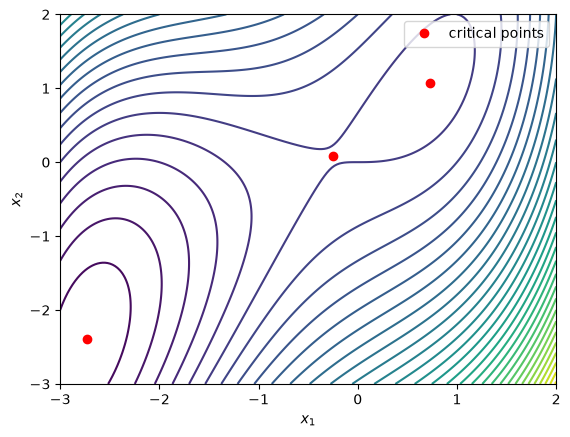

In [23]:
# plot the contour and critical points
ax = contour(f, (-3, 2), (-3, 2))
ax.plot(critical_points[:, 0], critical_points[:, 1], 'ro', label="critical points")
ax.legend()

## Results

the critical points are listed and classified above. the function around the critical points is bound below. so we can say that the minimum at [-2.732, -2.399], f(x) = - 22.726.

## Interpretation

same as in previous problems. veryfying the critical points is important to see if we found a minimum.